# Figure 5 · image-text retrieval on RxRx3-core

Retrieval between perturbation-level cell painting embeddings and text, for compounds and CRISPR knockouts
separately. PertOmni (boxes over 5 seeds) aggregates the 5 channels by their mean (Mean), by projecting each channel
and averaging (ProjMean) or by concatenation (Concat); CellCLIP is drawn as dotted (zero-shot) and dashed
(fine-tuned) lines. `image` = image -> text, `text` = text -> image.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")  # deprecation notices of the installed libraries
from pertomni import paths      # pip install -e . in the repository root
from pertomni.io import load_obj, save_obj

R = paths.DATA                  # published inputs and results (data/, or $PERTOMNI_DATA)
FIG = Path("figures")           # figures of this notebook, next to it
FIG.mkdir(exist_ok=True)
SEEDS = range(5)
# editable text in PDF / SVG (TrueType fonts, <text> elements)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})

In [2]:
from pertomni.evaluation.retrieval import benchmark

DATA = R / "cellclip_data"
MODELS = {"mean_all_cl_es_acc": "Mean_PertOmni", "per_channel_cl_es_acc": "ProjMean_PertOmni", "concat_cl_es_acc": "Concat_PertOmni"}
MODALITY = {"cmp": "Compound", "kd": "CRISPR"}

records = []
for model, label in MODELS.items():
    for seed in SEEDS:
        d = DATA / "rxrx3-core" / model / f"seed{seed}"
        for mod in MODALITY:
            scores, _ = benchmark(load_obj(d / f"test_{mod}_img_embeds.pkl"), load_obj(d / f"test_{mod}_txt_embeds.pkl"))
            records += [dict(Method=label, modality=mod, seed=seed, ScoreType=k, ScoreValue=v) for k, v in scores.items()]
df_all = pd.DataFrame(records)

# CellCLIP: perturbation-level features of the test set, split by the PertOmni perturbation lists
ref = DATA / "rxrx3-core" / "mean_all_cl_es_acc" / "seed0"
subsets = {mod: set(load_obj(ref / f"test_{mod}_perts.pkl")) for mod in MODALITY}
cellclip = {}
for name, folder in (("CellCLIP", "rxrx3_results"), ("ft_CellCLIP", "ft_rxrx3_results")):
    img, txt, perts = (load_obj(DATA / folder / f) for f in ("val_img_features.pkl", "val_text_features.pkl", "test_perts.pkl"))
    for mod, keep in subsets.items():
        idx = [i for i, p in enumerate(perts) if p in keep]
        cellclip[name, mod] = benchmark(img[idx], txt[idx], scale=True)[0]

table = df_all.groupby(["modality", "Method", "ScoreType"])["ScoreValue"].mean().unstack()
for (name, mod), s in cellclip.items():
    table.loc[(mod, name), :] = pd.Series(s)
table[["gene_acc@1", "gene_acc@10", "gene_mrr", "text_acc@1", "text_acc@10", "text_mrr"]].round(4)

ScoreType                   gene_acc@1  gene_acc@10  gene_mrr  text_acc@1  \
modality Method                                                             
cmp      Concat_PertOmni        0.0141       0.0732    0.0401      0.0220   
         Mean_PertOmni          0.0073       0.0648    0.0320      0.0169   
         ProjMean_PertOmni      0.0090       0.0670    0.0360      0.0197   
kd       Concat_PertOmni        0.0297       0.1484    0.0798      0.0281   
         Mean_PertOmni          0.0250       0.1219    0.0707      0.0188   
         ProjMean_PertOmni      0.0266       0.1266    0.0711      0.0266   
cmp      CellCLIP               0.0028       0.0338    0.0177      0.0028   
kd       CellCLIP               0.0078       0.0547    0.0381      0.0078   
cmp      ft_CellCLIP            0.0085       0.0394    0.0249      0.0056   
kd       ft_CellCLIP            0.0078       0.0938    0.0510      0.0156   

ScoreType                   text_acc@10  text_mrr  
modality Method                                    
cmp      Concat_PertOmni         0.1008    0.0540  
         Mean_PertOmni           0.0794    0.0450  
         ProjMean_PertOmni       0.0868    0.0488  
kd       Concat_PertOmni         0.1953    0.0870  
         Mean_PertOmni           0.1547    0.0764  
         ProjMean_PertOmni       0.1531    0.0804  
cmp      CellCLIP                0.0338    0.0193  
kd       CellCLIP                0.0703    0.0416  
cmp      ft_CellCLIP             0.0394    0.0235  
kd       ft_CellCLIP             0.0859    0.0530

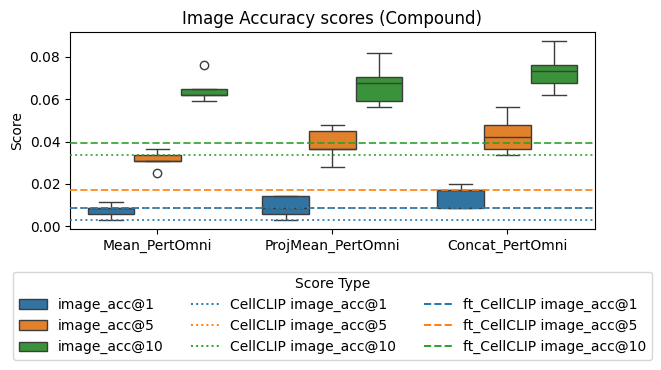

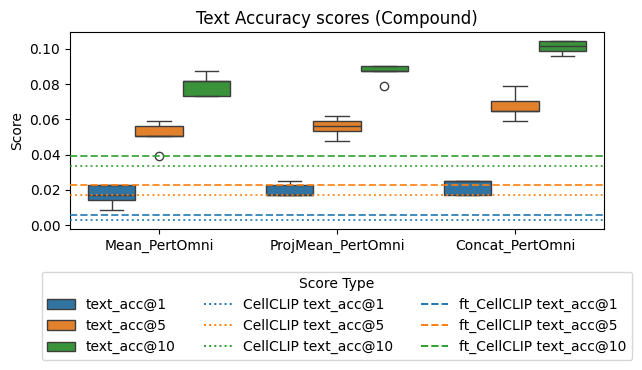

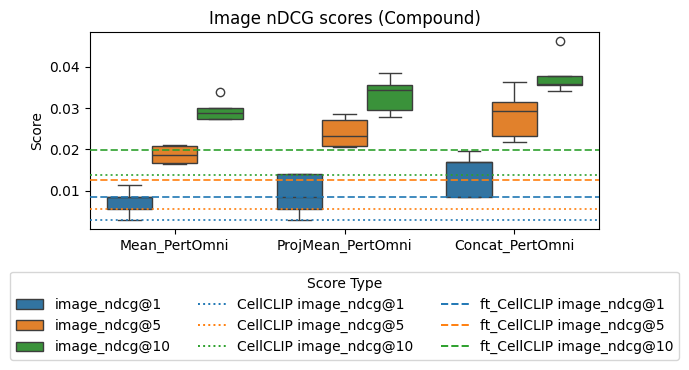

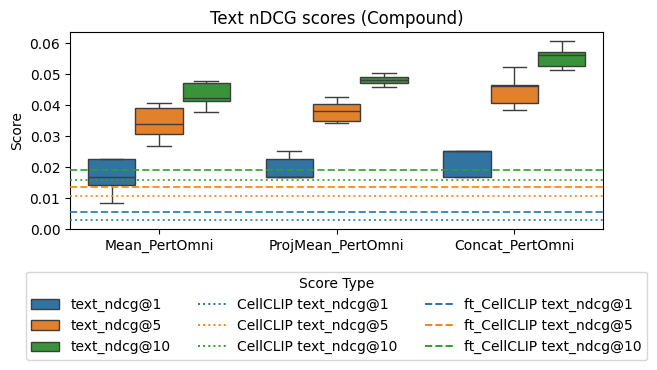

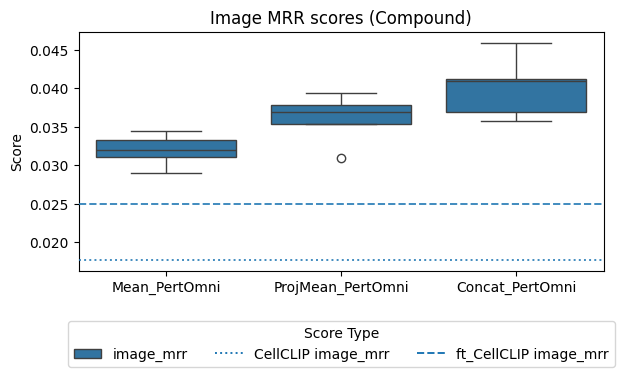

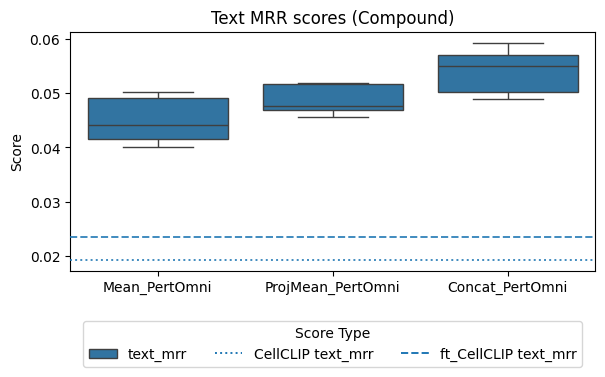

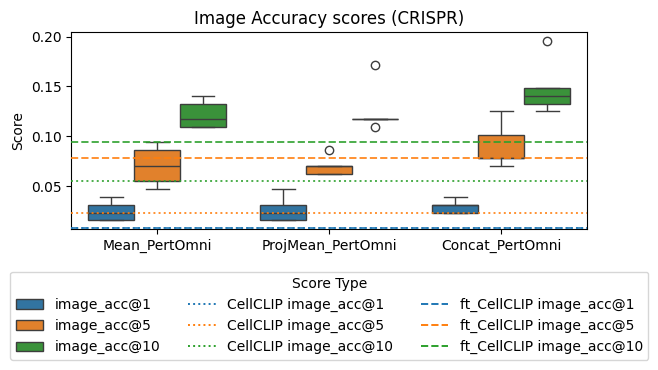

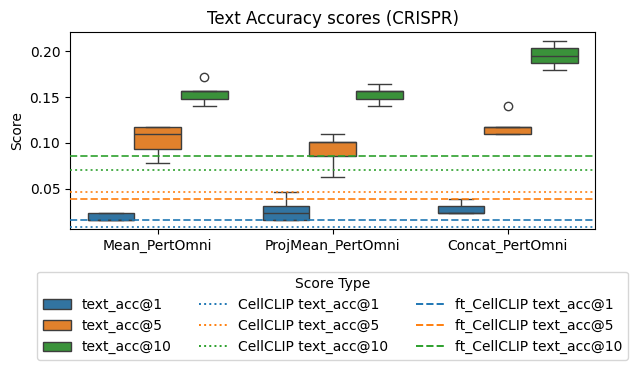

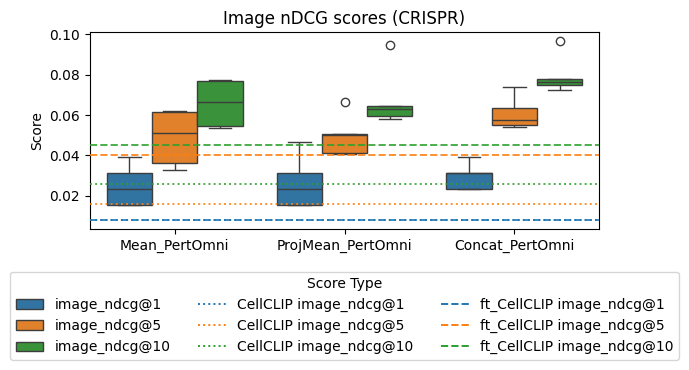

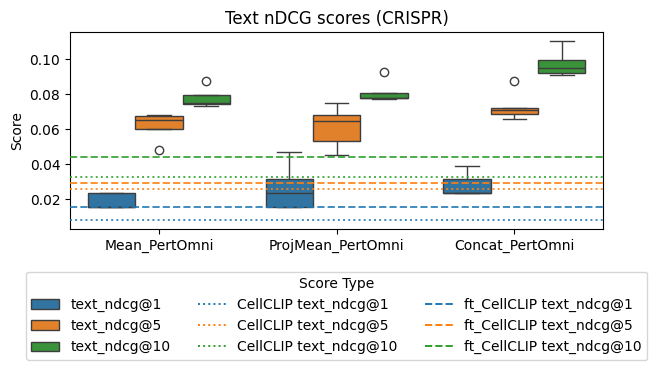

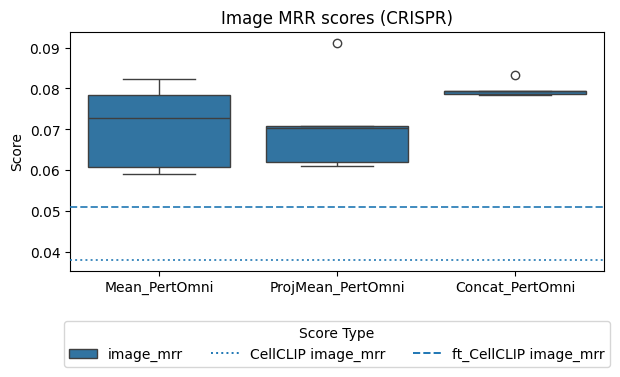

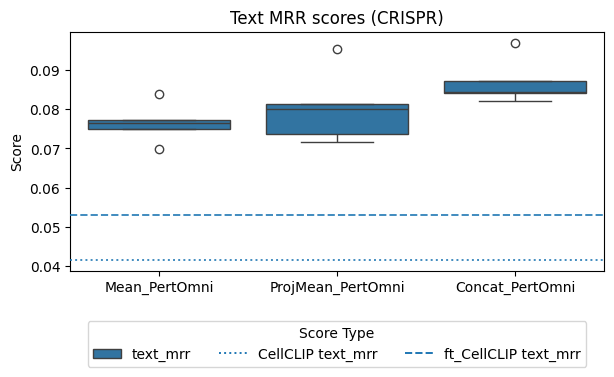

In [3]:
import matplotlib.lines as mlines
PALETTE = sns.color_palette()
GROUPS = {"Image Accuracy": ["gene_acc@1", "gene_acc@5", "gene_acc@10"], "Text Accuracy": ["text_acc@1", "text_acc@5", "text_acc@10"],
          "Image nDCG": ["gene_ndcg@1", "gene_ndcg@5", "gene_ndcg@10"], "Text nDCG": ["text_ndcg@1", "text_ndcg@5", "text_ndcg@10"],
          "Image MRR": ["gene_mrr"], "Text MRR": ["text_mrr"]}

def plot_scores(title, names, mod):
    d = df_all[df_all["ScoreType"].isin(names) & (df_all["modality"] == mod)]
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=d, x="Method", y="ScoreValue", hue="ScoreType", order=list(MODELS.values()), hue_order=names,
                palette=PALETTE[:len(names)], ax=ax)
    handles = []
    for model, ls in (("CellCLIP", ":"), ("ft_CellCLIP", "--")):
        for j, name in enumerate(names):
            ax.axhline(cellclip[model, mod][name], color=PALETTE[j], ls=ls, lw=1.4, alpha=0.85, zorder=3)
            handles.append(mlines.Line2D([], [], color=PALETTE[j], ls=ls, lw=1.4, label=f"{model} {name}"))
    box_handles, box_labels = ax.get_legend_handles_labels()
    labels = [l.replace("gene_", "image_") for l in box_labels + [h.get_label() for h in handles]]
    ax.legend(box_handles + handles, labels, title="Score Type", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, framealpha=0.8)
    ax.set_title(f"{title} scores ({MODALITY[mod]})")
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    fig.tight_layout(rect=[0, 0, 0.78, 1])
    fig.savefig(FIG / f"boxplot_{title.replace(' ', '_')}_{mod}.pdf", bbox_inches="tight")
    plt.show()

for mod in MODALITY:
    for title, names in GROUPS.items():
        plot_scores(title, names, mod)